Aula 03 - Primeiro exemplo de algoritmo de Machine Learning 

In [1]:
# instalação biblioteca pandas
!pip install pandas

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# instalação biblioteca matplotlib
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# 1 Importação de bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
#importa o algoritmo de arvore de decisão e sua visualização
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
#importando a bilioteca para dividir os dados em treino e teste
from sklearn.model_selection import train_test_split
# Importando a biblioteca para calcular as métricas do modelo de Machine Learning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay

)
#Confusion_matriz calcula a matriz de confusão, e ConfusionMatrixDisplay exibe a matriz de confusão

In [5]:
#2 Criação do conjunto de dados
#Criando um conjunto de dados de 20 máquinas industriais
dados = {
    #Quantidade de peças produzidas por cada máquina
    "producao":[1000,500,1200,400,1100,300,950,450,1050,550,1300,600,1150,350,900,
                650,1250,480,1080,520],
    "energia":[200,250,240,300,220,280,210,270,230,310,260,290,235,260,195,320,250,295,225,275],
    "eficiente":[1,0,1,0,1,
                 0,1,0,1,0,
                 1,0,1,0,1,
                 0,1,0,1,0]
}
# Transforma o dicionario em um DataFrame com o Pandas
df = pd.DataFrame(dados)

In [6]:
#Exibindo as primeiras  linhas do DataFrame
df.head(20)

,producao,energia,eficiente
0,1000,200,1
1,500,250,0
2,1200,240,1
3,400,300,0
4,1100,220,1
5,300,280,0
6,950,210,1
7,450,270,0
8,1050,230,1
9,550,310,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   producao   20 non-null     int64
 1   energia    20 non-null     int64
 2   eficiente  20 non-null     int64
dtypes: int64(3)
memory usage: 612.0 bytes


In [8]:
# 3 Separação das variáveis independentes (X) e dependentes (y)
# Variavel independente (X) - produção e energia
X = df[["producao", "energia"]]
# Variavel dependente (y)-eficiente
y = df['eficiente']

In [18]:

df['producao'].min()

np.int64(300)

In [19]:
df["producao"].max()

np.int64(1300)

In [9]:
print(X)


    producao  energia
0       1000      200
1        500      250
2       1200      240
3        400      300
4       1100      220
5        300      280
6        950      210
7        450      270
8       1050      230
9        550      310
10      1300      260
11       600      290
12      1150      235
13       350      260
14       900      195
15       650      320
16      1250      250
17       480      295
18      1080      225
19       520      275


In [10]:
print(y)

0     1
1     0
2     1
3     0
4     1
5     0
6     1
7     0
8     1
9     0
10    1
11    0
12    1
13    0
14    1
15    0
16    1
17    0
18    1
19    0
Name: eficiente, dtype: int64


In [11]:
#4 Divisão do conjunto de dados em treino e teste
X_treino,X_teste,y_treino,y_teste = train_test_split(X, #Variaveis de entrada
                                                     y, #Cassificação conhecida
                                                     test_size=0.2, #Reserva 20% dos dados para teste
                                                     random_state=42,# Aleatoriedade da divisão dos dados
                                                     stratify=y) # Preserva a proporção de classes na divisão dos dados

# Exibindo a quanttidade de amostras em cada conjunto
print("Quantidade de amostras no conjunto de treino:", len(X_treino))
print("Quantidade de amostras no conjunto de teste:", len(X_teste))

Quantidade de amostras no conjunto de treino: 16
Quantidade de amostras no conjunto de teste: 4


In [13]:
#5 Treinamento do modelo de Machine Learning 
modelo_arvore = DecisionTreeClassifier(random_state=42) #Cria o modelo de árvore de decisão
modelo_arvore.fit(X_treino, y_treino) #Treina o modelo com os dados de treino

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [15]:
# Teste do modelo criado de Machine Learning
previsao_arvore = modelo_arvore.predict(X_teste) #Realiza a previsão com os dados de teste
#Exibe as classificações reais e previstas
print("Valores reais:",y_teste.values)
print("Valores previstos:",previsao_arvore)

Valores reais: [0 0 1 1]
Valores previstos: [0 0 1 1]


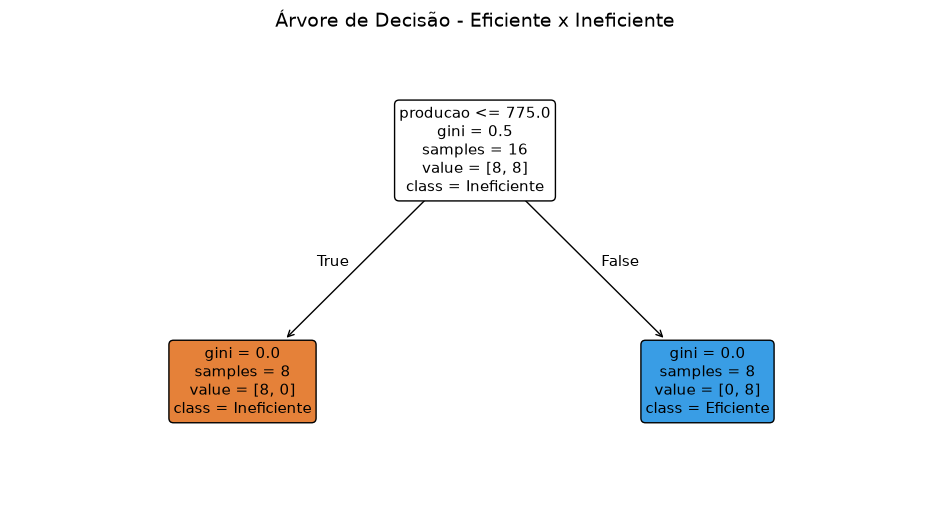

In [16]:
# 6 Visualização da Árvore de Decisão
plt.figure(figsize=(12,6)) #Define o tamanho da figura
# Desenha a árvore treinada, com os nomes das variáveis independentes e as classes da variável dependente
plot_tree(modelo_arvore,
          # Nome das variáveis de entrada
          feature_names = ['producao','energia'],
          #Nome das classes de saída (0 e 1)
          class_names =['Ineficiente','Eficiente'],
          # Preenche os nós com cores de acordo com as classes
          filled = True,
          #Deixa as classes com bordas arredondadas
          rounded = True,
          #Define o tamanho das letras
          fontsize = 11
          )
# Adiciona um título 
plt.title("Árvore de Decisão - Eficiente x Ineficiente", fontsize=14)
# Exibe a figura
plt.show()

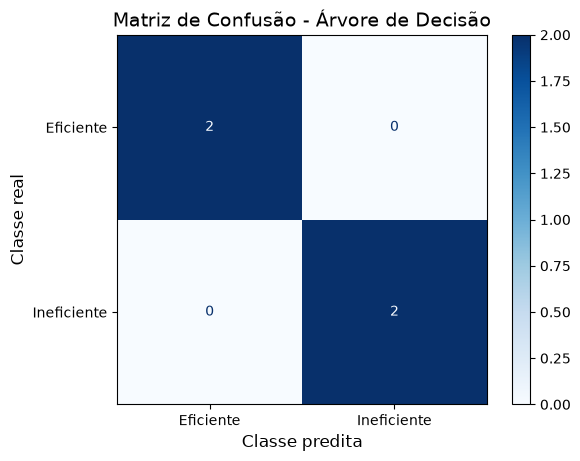

In [20]:
# Matriz de confusão para a arvore de decisão
# Calcula a matriz de confusao
matriz_arvore = confusion_matrix(y_teste, previsao_arvore,
                                 labels=[1,0] # Define a ordem das classes na matriz de confusão
                                 )

# Prepara a visualização da matriz de confusão
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_arvore,
                                display_labels=['Eficiente','Ineficiente'])
 # Define os rótulos das classes

 # Desenha a matriz de confusão utilizando a escala  de cores azul
disp.plot(cmap=plt.cm.Blues, values_format='d') #  cor azul da matriz de confusão e exibe os valores  dentro da matriz como inteiro
# Adiciona um título no gráfico     
plt.title("Matriz de Confusão - Árvore de Decisão", fontsize=14)
plt.xlabel("Classe predita", fontsize=12) # Adiciona o rótulo do eixo x
plt.ylabel("Classe real", fontsize=12) # Adiciona o rótulo do
# Exibe o resultado
plt.show()

In [21]:
# Calculando as métricas de avaliação do modelo de árvore de decisão
#Acurácia - proporção total de acertos do modelo
acuracia_arvore = accuracy_score(y_teste, previsao_arvore)

# Precisao - entre as máquina previstas como eficientes quantas realmente são eficientes
precisao_arvore = precision_score(y_teste, previsao_arvore)

# Revocação - entre as máquinas realmente eficientes quantas foram corretamente previstas
revocacao_arvore = recall_score(y_teste, previsao_arvore)

# F1-Score - média harmônica da precisão e da revocação
f1_arvore = f1_score(y_teste, previsao_arvore,zero_division=1) # zero_division=1 evita erro de divisão por zero caso não haja previsão positiva
# Exive os resultados das métricas
print("Métricas de avaliação do modelo de Árvore de Decisão:")
print(f"Acurácia: {acuracia_arvore:.2f}")   
print(f"Precisão: {precisao_arvore:.2f}")
print(f"Revocação: {revocacao_arvore:.2f}")
print(f"F1-Score: {f1_arvore:.2f}")

Métricas de avaliação do modelo de Árvore de Decisão:
Acurácia: 1.00
Precisão: 1.00
Revocação: 1.00
F1-Score: 1.00


In [22]:
# 7 - Treinamento do modelo de Random Forest
modelo_rf =RandomForestClassifier(
    n_estimators=100, #Número de árvores na floresta
    random_state=42) #Cria o modelo de Random Forest

In [23]:
# 8 - Treinamento do modelo de Random Forest
modelo_rf.fit(X_treino, y_treino) #Treina o modelo com

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [26]:
# 9 - Classifica as máquinas do conjunto de teste utilizando o modelo de Random Forest
previsao_rf = modelo_rf.predict(X_teste) #Realiza a previsão com os dados de teste
print("Previsão do modelo de Random Forest:", previsao_rf)
print("Valores reais:",y_teste.values)

Previsão do modelo de Random Forest: [0 0 1 1]
Valores reais: [0 0 1 1]


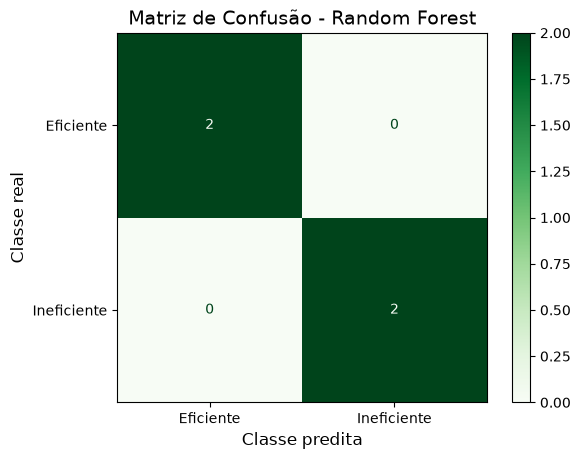

In [27]:
# 10 - Matriz de confusão para o modelo de Random Forest
# Calcula a matriz de confusao
matriz_rf = confusion_matrix(y_teste, previsao_rf, labels=[1, 0]) # Define a ordem das classes na matriz de confusão
# Prepara a visualização da matriz de confusão
disp_rf = ConfusionMatrixDisplay(confusion_matrix=matriz_rf,display_labels=['Eficiente','Ineficiente']) # Define os rótulos das classes
#Exibe a matriz em verde
disp_rf.plot(cmap=plt.cm.Greens, values_format='d') #  cor verde da matriz de confusão e exibe os valores  dentro da matriz como inteiro
plt.title("Matriz de Confusão - Random Forest", fontsize=14) # Adiciona um título no gráfico
plt.xlabel("Classe predita", fontsize=12) # Adiciona o rótulo do eixo x
plt.ylabel("Classe real", fontsize=12) # Adiciona o rótulo do eixo y
plt.show() # Exibe o resultado

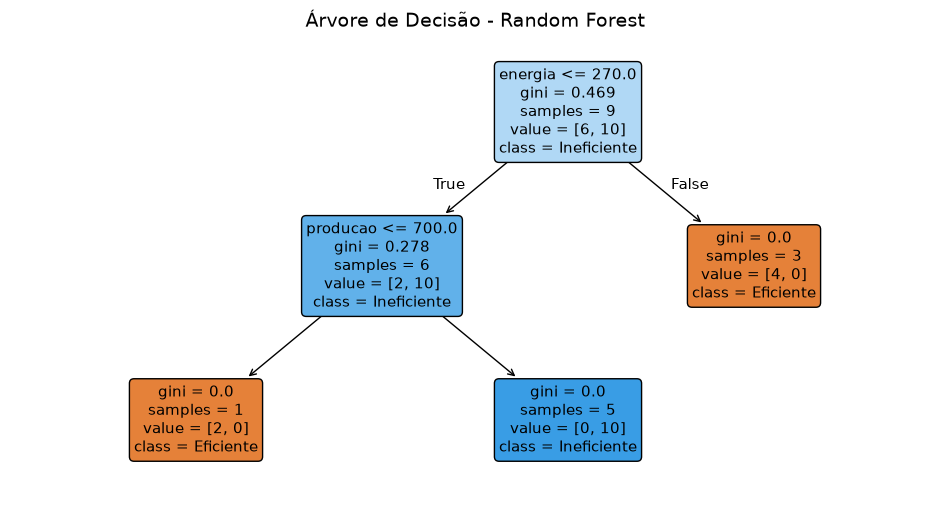

In [28]:
# Visualização de uma árvore do Random Forest
plt.figure(figsize=(12,6)) #Define o tamanho da figura
# Desenha a primeira árvore da floresta, com os nomes das variáveis independentes e as classes da variável dependente
plot_tree(modelo_rf.estimators_[0], #Seleciona a primeira árvore da floresta
          feature_names = ['producao','energia'], # Nome das variáveis de entrada
          class_names = ['Eficiente','Ineficiente'],
          filled=True,
          rounded=True,
          max_depth=2, # Limita a profundidade da árvore para melhor visualização
          fontsize=11
          ) # Nome das classes da variável dependente
plt.title("Árvore de Decisão - Random Forest", fontsize=14) # Adiciona um título no gráfico
plt.xlabel("Variáveis de Entrada", fontsize=12) # Adiciona o rótulo do eixo x
plt.ylabel("Classe", fontsize=12) # Adiciona o rótulo do eixo y
plt.show() # Exibe o resultado

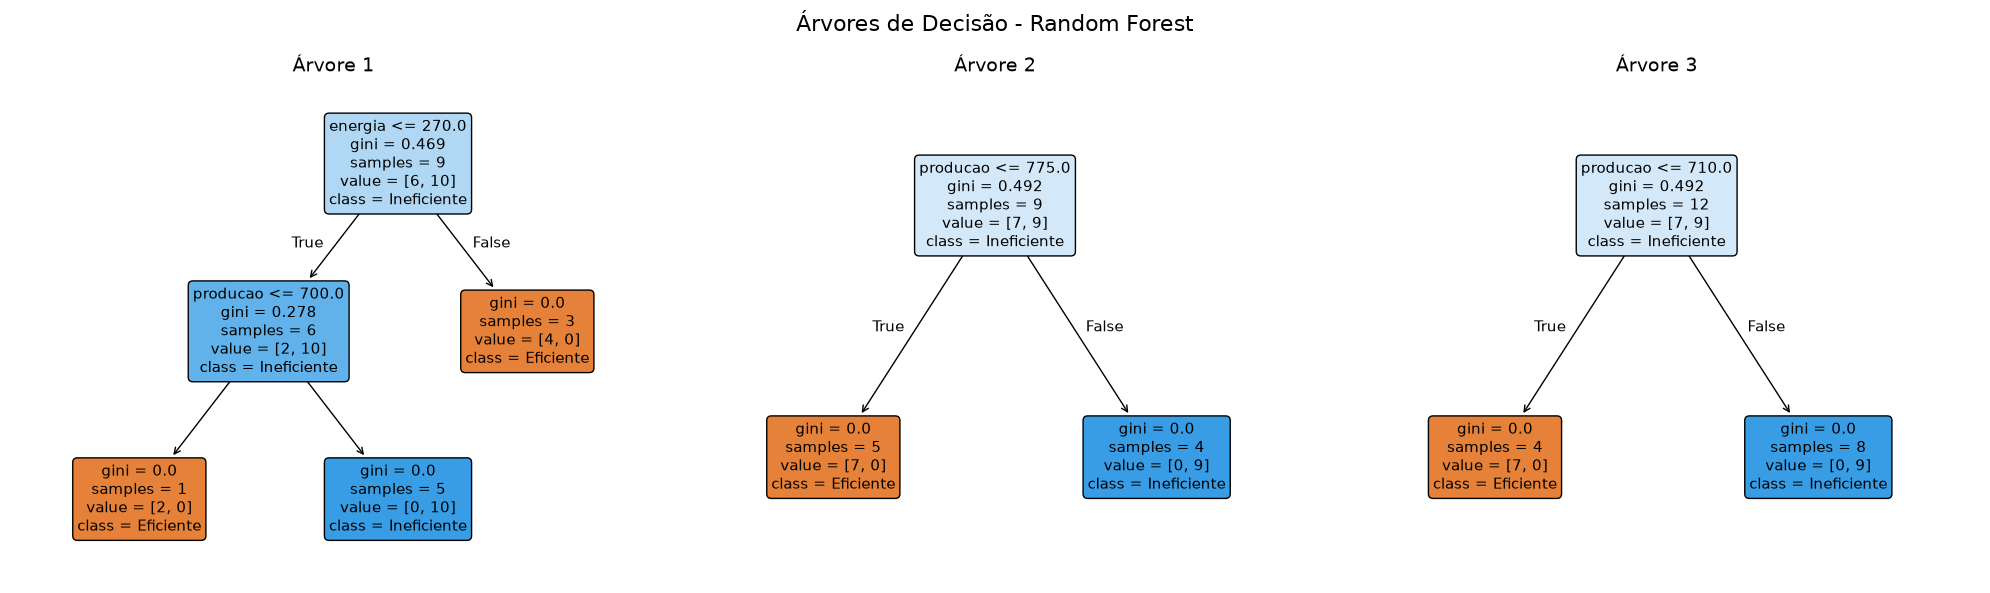

In [29]:
# Visualização de mais uma árvore de decisão do Random Forest
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
#Criar uma figura com três gráficos lado a lado
# plt.subplots(nrows, ncols, figsize=(width, height)) cria uma figura com nrows linhas e ncols colunas de subplots, e define o tamanho da figura em polegadas (width, height).
fig, axes = plt.subplots(1,3   ,figsize=(20,6)) # Define o tamanho da figura
# Percorre as três primeiras árvores da floresta e desenha cada uma em um subplot
for i in range(3):
    plot_tree(modelo_rf.estimators_[i], #Seleciona a i-ésima árvore da floresta
              feature_names = ['producao','energia'], # Nome das variáveis de entrada
              class_names = ['Eficiente','Ineficiente'],
              filled=True,
              rounded=True,
              max_depth=2, # Limita a profundidade da árvore para melhor visualização
              fontsize=11,
              ax=axes[i] # Define o subplot onde a árvore será desenhada
              )
    axes[i].set_title(f"Árvore {i+1}", fontsize=14) # Adiciona um título no subplot
plt.suptitle("Árvores de Decisão - Random Forest", fontsize=16) # Adiciona um título geral na figura
plt.tight_layout() # Ajusta o layout da figura para evitar sobreposição de elementos
plt.show() # Exibe o resultado